# Почему после отбора меняется доля GoA
## Эксперимент A · структура эффекта

Предыдущий этап сохранен коммитом `49813c2`. Здесь рассматриваем три вопроса:
меняются ли веса аэропортов, сохраняются ли различия внутри аэропорта и месяца,
как пересекаются отсутствие типа самолета и отсутствие пригодного C40?

**Результат – арифметическое разложение наблюдаемых долей, а не причинная модель.**
Единица анализа остается записью события с исходной меткой. Новые исключения,
изменение данных и обучение модели не выполняются.

## 1. Зафиксированный протокол

Повторно агрегируем весь источник по аэропорту, месяцу UTC, отсутствию исходного
typecode и первой причине невхождения. Null и точная пустая строка typecode
образуют одну группу; пробелы и регистр остальных значений не исправляются.
Для каждого сочетания сохраняем объем и число GoA. Маски идентичны эксперименту A.
Финальные совместные агрегаты независимо сравниваем с фактическим итоговым Parquet.

Разложение выполняем по аэропортам, месяцам, аэропортам × месяцам и
аэропортам × месяцам × отсутствию типа. Все группы входят в расчет.
Для демонстрации разрыва сохранения по меткам используем N источника ≥ 1000
и ≥ 20 исходных GoA на ячейку; полный экспорт сохраняет все ячейки.
Порог служит для отображения, не для фильтрации популяции или вывода о значимости.

Предметный разбор: LTFJ, EGCC, EIDW и отсутствие typecode. Месяцы с нулевым
финальным покрытием не получают искусственную долю GoA=0. Отдельно показываем
популяцию общей поддержки – группы, имеющие наблюдения в финале.

In [1]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams['axes.prop_cycle']=cycler(color=['#D65A4A','#00897B','#E69A90','#80CBC4'])

import matplotlib.dates as mdates
from IPython.display import display, Markdown

ROOT=Path.cwd().resolve()
while not (ROOT/'scripts/build_structure_notebook.py').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Не найден корень исследования')
    ROOT=ROOT.parent
DATA_ROOT=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))
R=ROOT/'reports'; F=ROOT/'figures'
BASE=json.loads((R/'verification.json').read_text(encoding='utf-8'))
assert all(c['passed'] for c in BASE['ordered_checks'])
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
KEY=['flight_id','icao24','airport','landing_time']
GROUP=['airport','month','type_missing']
STAGES=['source','pairs','complete','temporal','final']
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for b in iter(lambda:stream.read(8*1024*1024),b''): h.update(b)
    return h.hexdigest()
def local(rel): return DATA_ROOT/rel.replace(chr(92),'/')
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']: plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
inputs={v['stage']:v for v in BASE['inputs'] if v['stage'] in ['source','final']}
for item in inputs.values(): assert sha(local(item['file']))==item['sha256']
archives=[v for v in BASE['inputs'] if v['stage']=='exclusion_archive']
archive_keys=[]
for item in archives:
    assert sha(local(item['file']))==item['sha256']
    archive_keys.append(pq.read_table(local(item['file']),columns=KEY).to_pandas(ignore_metadata=True))
pair_keys=pd.MultiIndex.from_frame(archive_keys[0])
manual_keys=pd.MultiIndex.from_frame(pd.concat(archive_keys[1:],ignore_index=True))
assert len(pair_keys)==294 and len(manual_keys)==9

## 2. Совместные агрегаты из исходных записей

Код читает исходные поля, а не старые диагностические флаги. Дополнительная
таблица описывает каждый шаблон отсутствия четырех полей C40. Пропуск и
неконечное число различаются. Временной критерий – C40 строго раньше первого
элемента attempt_times; пустой список требует остановки.

In [2]:
chunks=[]; pattern_chunks=[]; pair_found=manual_found=0
columns=list(dict.fromkeys(KEY+['GoA','typecode','attempt_times','C40_CROSS_TIME',
                               'C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON']))
for i,batch in enumerate(pq.ParquetFile(local(inputs['source']['file'])).iter_batches(
        batch_size=100_000,columns=columns)):
    t=pa.Table.from_batches([batch])
    f=t.select([c for c in columns if c!='attempt_times']).to_pandas(ignore_metadata=True)
    assert f[KEY+['GoA']].notna().all().all()
    lengths=pc.fill_null(pc.list_value_length(t['attempt_times']),0).to_numpy()
    assert (lengths>0).all()
    first=pc.list_element(t['attempt_times'],0).to_numpy().astype('datetime64[ns]')
    c40=f.C40_CROSS_TIME.to_numpy(dtype='datetime64[ns]')
    fields=['C40_CROSS_TIME','C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON']
    missing=f[fields].isna()
    complete=~missing.any(axis=1).to_numpy()
    finite=np.isfinite(f[fields[1:]].to_numpy()).all(axis=1)
    first_ok=~np.isnat(first); before=first_ok&(c40<first)
    index=pd.MultiIndex.from_frame(f[KEY])
    pair=index.isin(pair_keys); manual=index.isin(manual_keys)
    pair_found+=int(pair.sum()); manual_found+=int(manual.sum())
    f['reason']=np.select([pair,~complete,~finite,~first_ok,~before,manual],
      ['ambiguous_pair','missing_c40','nonfinite_c40','missing_first_attempt',
       'c40_not_before_first_attempt','manual_case'],default='retained')
    f['month']=f.landing_time.dt.strftime('%Y-%m')
    f['type_missing']=f.typecode.isna()|f.typecode.eq('')
    chunks.append(f.groupby(GROUP+['reason'],dropna=False).GoA.agg(rows='size',goa='sum').reset_index())
    # Биты: время=8, направление=4, широта=2, долгота=1.
    f['c40_missing_pattern']=missing.to_numpy(dtype=np.uint8)@np.array([8,4,2,1],dtype=np.uint8)
    pattern_chunks.append(f.groupby(GROUP+['c40_missing_pattern'],dropna=False).GoA.agg(
                             rows='size',goa='sum').reset_index())
    if i%20==0: print(f'Блок {i+1}: совместные разрезы рассчитаны')
joint=pd.concat(chunks).groupby(GROUP+['reason'],dropna=False)[['rows','goa']].sum().reset_index()
patterns=pd.concat(pattern_chunks).groupby(GROUP+['c40_missing_pattern'],dropna=False)[['rows','goa']].sum().reset_index()
assert pair_found==294 and manual_found==9
joint.to_csv(R/'joint_exclusion_reasons.csv',index=False)
patterns.to_csv(R/'joint_c40_missing_patterns.csv',index=False)
eligibility={
 'source':set(joint.reason),
 'pairs':set(joint.reason)-{'ambiguous_pair'},
 'complete':{'missing_first_attempt','c40_not_before_first_attempt','manual_case','retained'},
 'temporal':{'manual_case','retained'}, 'final':{'retained'}}
stages=[]
for s,allowed in eligibility.items():
    a=joint[joint.reason.isin(allowed)].groupby(GROUP,dropna=False)[['rows','goa']].sum().reset_index()
    a['stage']=s; stages.append(a)
joint_stages=pd.concat(stages,ignore_index=True)
joint_stages.to_csv(R/'joint_all_stages.csv',index=False)
previous=pd.read_csv(R/'selection_summary.csv').set_index('stage')[['rows','goa']]
pd.testing.assert_frame_equal(joint_stages.groupby('stage')[['rows','goa']].sum().sort_index(),
                              previous.sort_index(),check_dtype=False)
# Независимая проверка финальных совместных групп по фактическому файлу.
actual=[]
for batch in pq.ParquetFile(local(inputs['final']['file'])).iter_batches(
        batch_size=100_000,columns=['airport','landing_time','typecode','GoA']):
    f=batch.to_pandas(ignore_metadata=True)
    f['month']=f.landing_time.dt.strftime('%Y-%m')
    f['type_missing']=f.typecode.isna()|f.typecode.eq('')
    actual.append(f.groupby(GROUP,dropna=False).GoA.agg(rows='size',goa='sum').reset_index())
actual=pd.concat(actual).groupby(GROUP)[['rows','goa']].sum().sort_index()
expected=joint_stages[joint_stages.stage=='final'].set_index(GROUP)[['rows','goa']].sort_index()
pd.testing.assert_frame_equal(actual,expected,check_dtype=False)
verification={'source_sha256':inputs['source']['sha256'],'final_sha256':inputs['final']['sha256'],
 'source_rows':int(joint.rows.sum()),'source_goa':int(joint.goa.sum()),
 'pair_matches':pair_found,'manual_matches':manual_found,
 'all_stage_totals_match':True,'actual_final_joint_groups_match':True}
(R/'structure_verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
display(joint_stages.groupby('stage')[['rows','goa']].sum().reindex(STAGES))

Блок 1: совместные разрезы рассчитаны


Блок 21: совместные разрезы рассчитаны


Блок 41: совместные разрезы рассчитаны


Блок 61: совместные разрезы рассчитаны


,rows,goa
stage,,
source,7984254,26253
pairs,7983960,26250
complete,6331578,18403
temporal,6331494,18358
final,6331485,18349


## 3. Разложение изменения частоты

Пусть $w_{0g},p_{0g}$ – исходный вес группы и доля GoA,
$w_{1g},p_{1g}$ – соответствующие величины в финале.

$$p_1-p_0=\underbrace{\sum_g(w_{1g}-w_{0g})p_{0g}}_{\text{изменение весов}}
+\underbrace{\sum_g w_{1g}(p_{1g}-p_{0g})}_{\text{изменение внутри групп}}.$$

Используем **исходные доли как опорные**. Для исчезнувших групп $w_1=0$,
внутренний вклад равен нулю; неизвестная финальная доля не оценивается.
Разложение зависит от группировки и выбора опоры. Компоненты могут иметь
противоположные знаки; процент «объясненной разницы» тогда вводит в заблуждение.
Результаты выражены в процентных пунктах. Проверяем арифметическое равенство.

Отдельно выделяем изменение при ограничении источника группами общей поддержки:
$p_1-p_0=(p_{0,common}-p_0)+(p_1-p_{0,common})$. Это условное сравнение состава,
не предложение изменить источник или вернуть исключенные записи.

,source_goa_pct,final_goa_pct,delta_pp,composition_pp,within_pp,absent_group_support_pp,common_support_delta_pp,source_rows_without_final_support,source_goa_without_final_support
grouping,,,,,,,,,
airport,0.32881,0.28981,-0.03900,-0.01500,-0.02400,-0.01501,-0.02399,387368,2414
month,0.32881,0.28981,-0.03900,-0.00112,-0.03789,0.00000,-0.03900,0,0
airport_month,0.32881,0.28981,-0.03900,-0.01581,-0.02319,-0.01592,-0.02309,493464,2815
airport_month_type_missing,0.32881,0.28981,-0.03900,-0.01861,-0.02039,-0.01592,-0.02309,494124,2817


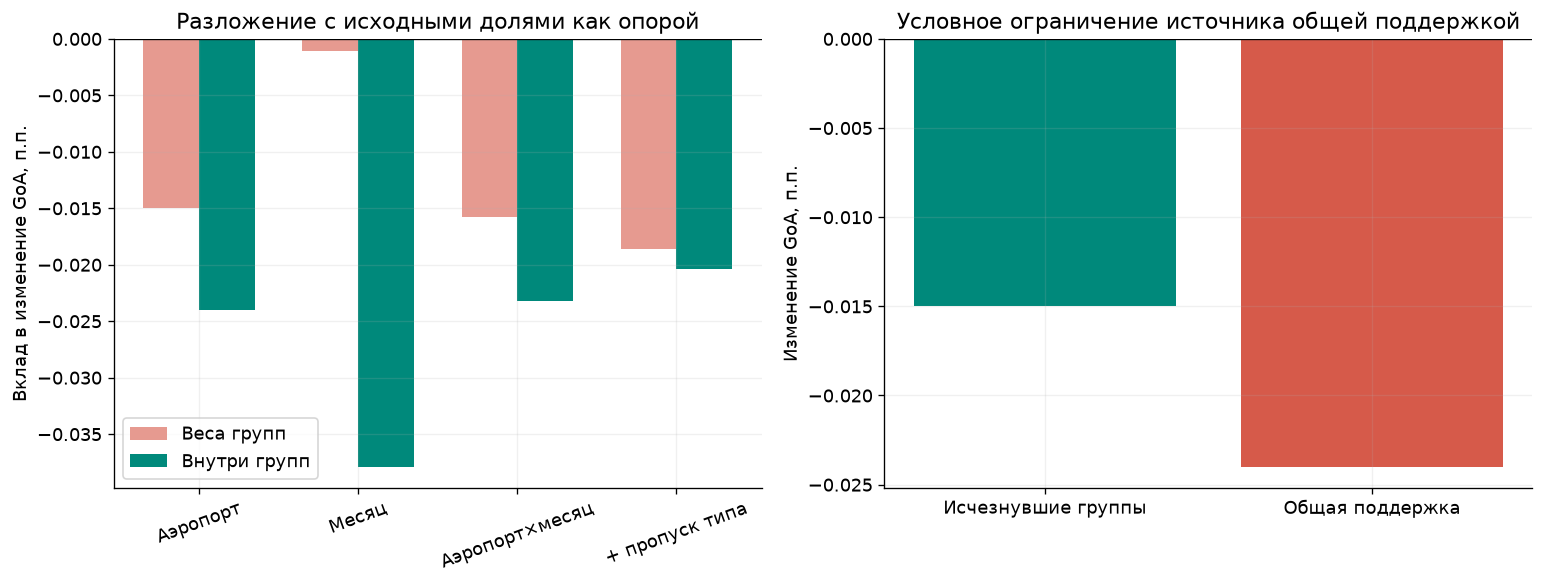

,rows_source,rows_final,p0,p1,composition_pp,within_pp
airport,,,,,,
EIDW,313008,263879.00000,0.00432,0.00349,0.00107,-0.00344
EHAM,639766,561481.00000,0.00221,0.00185,0.00189,-0.00321
EDDF,644881,604960.00000,0.00335,0.00311,0.00495,-0.00226
LSZH,372304,316973.00000,0.00399,0.00361,0.00137,-0.00191
EDDB,216588,148336.00000,0.00369,0.00288,-0.00136,-0.00190
LEMD,592140,515044.00000,0.00212,0.00191,0.00152,-0.00170
LOWW,360091,293578.00000,0.00382,0.00348,0.00048,-0.00158
LIRF,391269,322749.00000,0.00172,0.00144,0.00034,-0.00139
LSGG,255263,205372.00000,0.00298,0.00257,0.00014,-0.00132


In [3]:
def compare(groups):
    a=joint_stages.groupby(groups+['stage'],dropna=False)[['rows','goa']].sum().reset_index()
    s=a[a.stage=='source'].set_index(groups)[['rows','goa']].add_suffix('_source')
    f=a[a.stage=='final'].set_index(groups)[['rows','goa']].add_suffix('_final')
    c=s.join(f,how='left').fillna({'rows_final':0,'goa_final':0})
    c['w0']=c.rows_source/c.rows_source.sum(); c['w1']=c.rows_final/c.rows_final.sum()
    c['p0']=c.goa_source/c.rows_source
    c['p1']=c.goa_final/c.rows_final.replace(0,np.nan)
    c['composition_pp']=100*(c.w1-c.w0)*c.p0
    c['within_pp']=100*c.w1*(c.p1.fillna(c.p0)-c.p0)
    c['retained_pct']=100*c.rows_final/c.rows_source
    c['positive_retained_pct']=100*c.goa_final/c.goa_source.replace(0,np.nan)
    c['negative_retained_pct']=100*(c.rows_final-c.goa_final)/(c.rows_source-c.goa_source).replace(0,np.nan)
    c['label_retention_gap_pp']=c.positive_retained_pct-c.negative_retained_pct
    c['delta_goa_pp']=100*(c.p1-c.p0)
    c['goa_outside']=c.goa_source-c.goa_final
    c['rows_outside']=c.rows_source-c.rows_final
    return c

definitions={'airport':['airport'],'month':['month'],'airport_month':['airport','month'],
             'airport_month_type_missing':['airport','month','type_missing']}
comparisons={}; decompositions=[]
for name,groups in definitions.items():
    c=compare(groups); comparisons[name]=c; c.to_csv(R/f'structure_{name}.csv')
    p0=c.goa_source.sum()/c.rows_source.sum(); p1=c.goa_final.sum()/c.rows_final.sum()
    delta=100*(p1-p0); composition=c.composition_pp.sum(); within=c.within_pp.sum()
    assert np.isclose(delta,composition+within,atol=1e-12)
    common=c.rows_final>0
    pcommon=c.loc[common,'goa_source'].sum()/c.loc[common,'rows_source'].sum()
    support=100*(pcommon-p0); common_delta=100*(p1-pcommon)
    assert np.isclose(delta,support+common_delta,atol=1e-12)
    decompositions.append({'grouping':name,'source_goa_pct':100*p0,'final_goa_pct':100*p1,
       'delta_pp':delta,'composition_pp':composition,'within_pp':within,
       'absent_group_support_pp':support,'common_support_delta_pp':common_delta,
       'source_rows_without_final_support':int(c.loc[~common,'rows_source'].sum()),
       'source_goa_without_final_support':int(c.loc[~common,'goa_source'].sum())})
decomposition=pd.DataFrame(decompositions).set_index('grouping')
decomposition.to_csv(R/'rate_decomposition.csv')
display(decomposition.style.format(precision=5))
fig,axes=plt.subplots(1,2,figsize=(13,5))
x=np.arange(len(decomposition)); width=.35
axes[0].bar(x-width/2,decomposition.composition_pp,width,label='Веса групп',color='#E69A90')
axes[0].bar(x+width/2,decomposition.within_pp,width,label='Внутри групп',color='#00897B')
axes[0].axhline(0,color='black',lw=.8); axes[0].set_ylabel('Вклад в изменение GoA, п.п.')
axes[0].set_xticks(x,['Аэропорт','Месяц','Аэропорт×месяц','+ пропуск типа'],rotation=20)
axes[0].legend(); axes[0].set_title('Разложение с исходными долями как опорой')
airport=decomposition.loc['airport']
axes[1].bar(['Исчезнувшие группы','Общая поддержка'],
             [airport.absent_group_support_pp,airport.common_support_delta_pp],color=['#00897B','#D65A4A'])
axes[1].axhline(0,color='black',lw=.8); axes[1].set_ylabel('Изменение GoA, п.п.')
axes[1].set_title('Условное ограничение источника общей поддержкой')
save('09_rate_decomposition')
display(comparisons['airport'][['rows_source','rows_final','p0','p1','composition_pp','within_pp']]
        .sort_values('within_pp').style.format(precision=5))

## 4. Аэропорт × месяц: покрытие и метки

Тепловая карта включает весь наблюдаемый период. Белая ячейка означает отсутствие
исходных наблюдений, ноль – отсутствие сохраненных при наличии исходных.
Вторая карта показывает разрыв сохранения GoA=True и GoA=False; ячейки малых
объемов скрыты только на рисунке.

,airport,start_month,end_month,observed_months,rows_source,goa_source,reasons
0,EGCC,2021-03,2023-01,23,106096,401,missing_c40
1,LTFJ,2019-01,2023-05,53,387368,2414,missing_c40


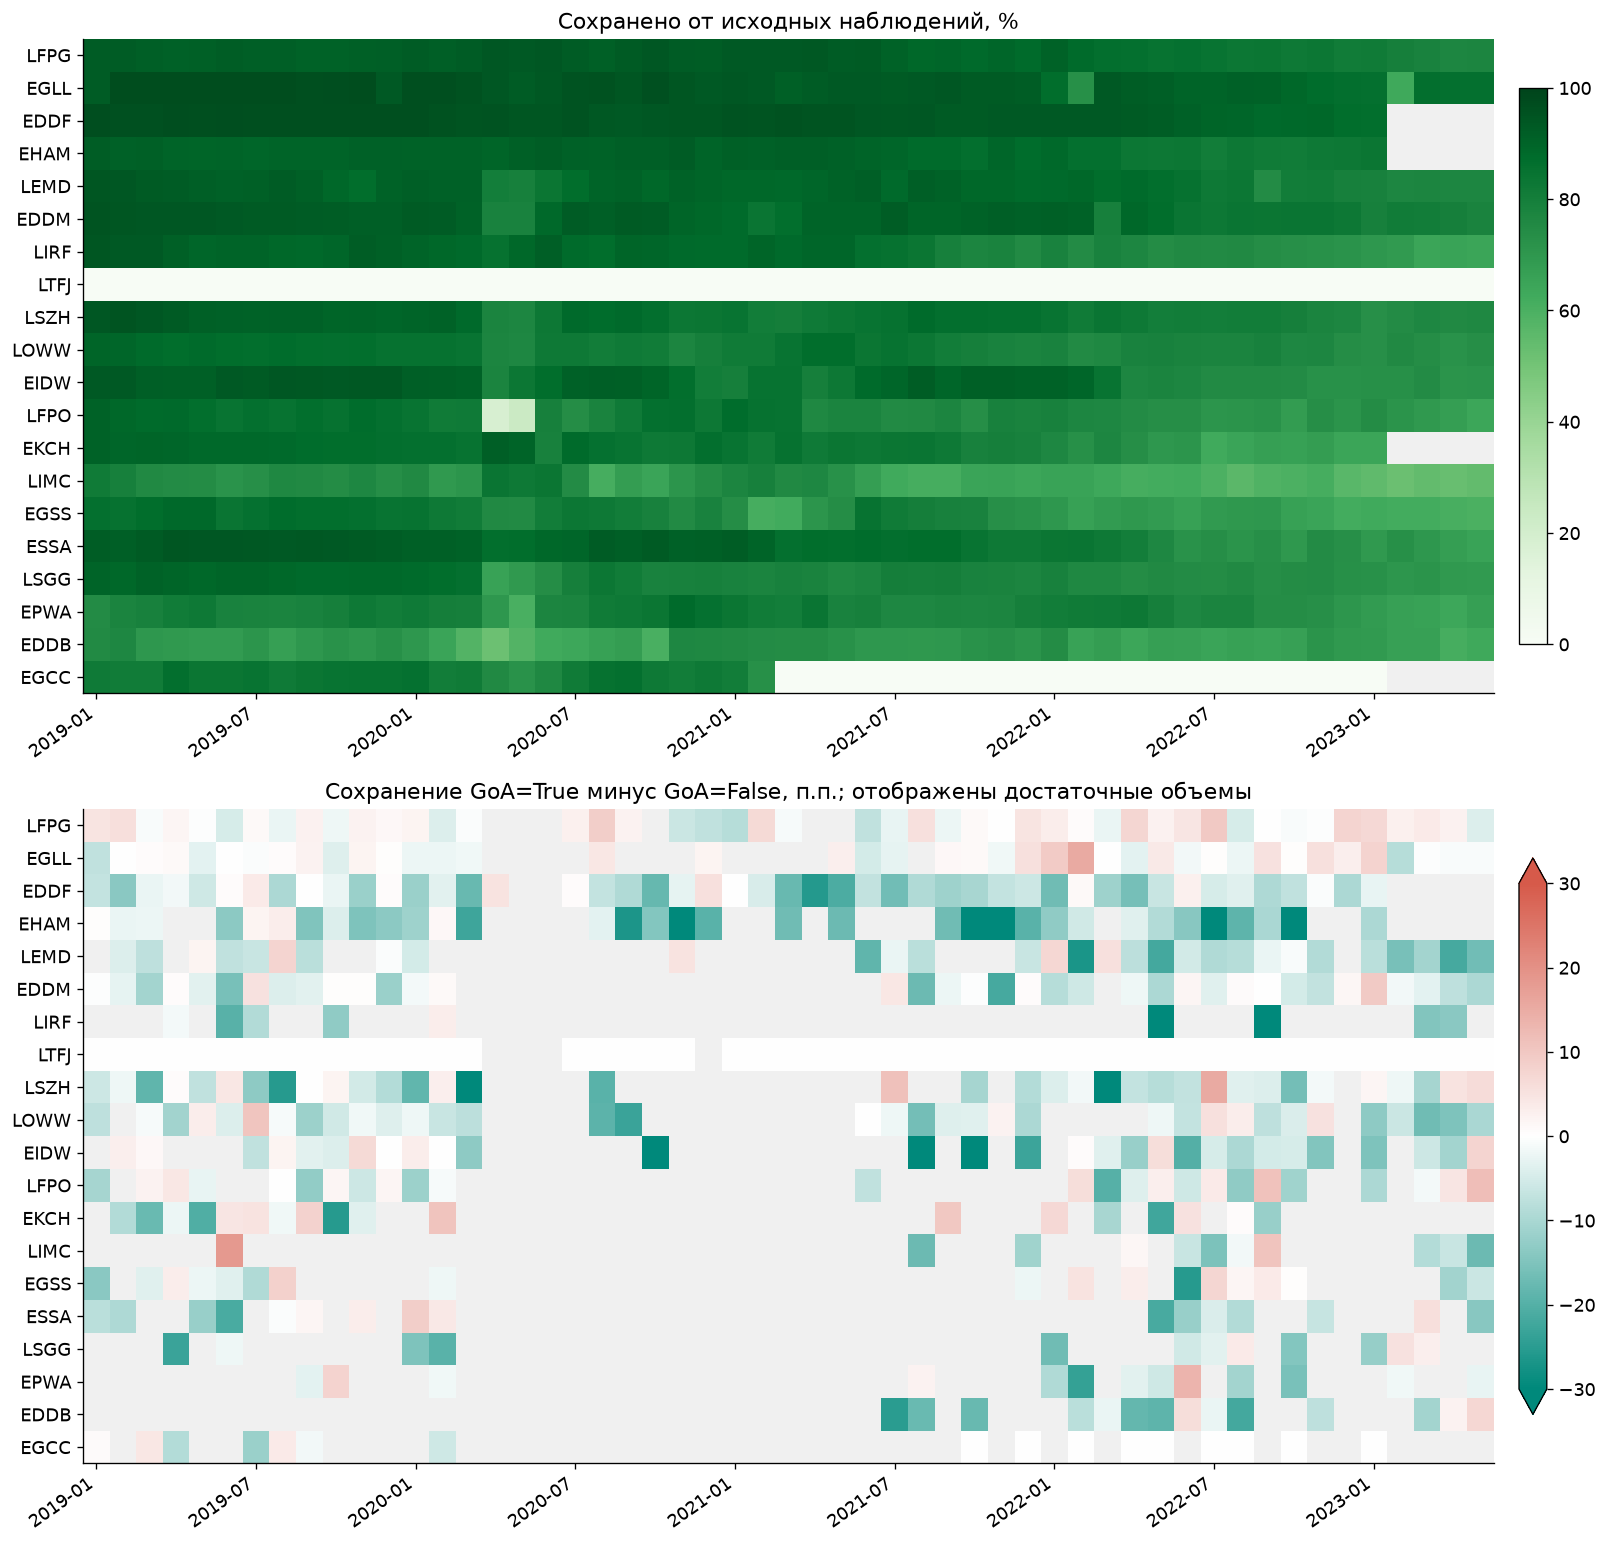

,airport,month,rows_source,goa_source,rows_final,goa_final,positive_retained_pct,negative_retained_pct,label_retention_gap_pp
819,LIRF,2022-05,9727,46,7247.000,7.000,15.217,74.786,-59.568
344,EHAM,2021-11,14008,23,12477.000,11.000,47.826,89.138,-41.312
392,EIDW,2021-10,5896,22,5370.000,11.000,50.000,91.233,-41.233
976,LSZH,2022-03,6846,21,5744.000,9.000,42.857,84.029,-41.172
332,EHAM,2020-11,6646,23,6142.000,12.000,52.174,92.556,-40.382
355,EHAM,2022-10,18788,39,15232.000,16.000,41.026,81.156,-40.131
390,EIDW,2021-08,5226,36,4805.000,19.000,52.778,92.216,-39.438
380,EIDW,2020-10,2616,25,2343.000,13.000,52.000,89.927,-37.927
823,LIRF,2022-09,10673,22,7909.000,9.000,40.909,74.171,-33.262
952,LSZH,2020-03,5122,34,4515.000,19.000,55.882,88.365,-32.482


In [4]:
am=comparisons['airport_month'].reset_index()
zero_windows=[]
for airport,a in am.groupby('airport'):
    z=a.loc[a.rows_final.eq(0)&a.rows_source.gt(0)].sort_values('month').copy()
    if z.empty: continue
    ordinal=z.month.map(lambda m:pd.Period(m,freq='M').ordinal)
    z['run']=ordinal.diff().ne(1).cumsum()
    for _,window in z.groupby('run'):
        reasons=joint.loc[(joint.airport==airport)&joint.month.isin(window.month),'reason'].unique()
        zero_windows.append({'airport':airport,'start_month':window.month.min(),
          'end_month':window.month.max(),'observed_months':len(window),
          'rows_source':int(window.rows_source.sum()),'goa_source':int(window.goa_source.sum()),
          'reasons':'; '.join(sorted(reasons))})
zero_windows=pd.DataFrame(zero_windows).sort_values(['airport','start_month'])
zero_windows.to_csv(R/'zero_coverage_windows.csv',index=False); display(zero_windows)
airports=comparisons['airport'].rows_source.sort_values(ascending=False).index
months=sorted(am.month.unique())
coverage=am.pivot(index='airport',columns='month',values='retained_pct').reindex(index=airports,columns=months)
eligible=(am.rows_source>=1000)&(am.goa_source>=20)
gap=am.assign(display_gap=am.label_retention_gap_pp.where(eligible)).pivot(
        index='airport',columns='month',values='display_gap').reindex(index=airports,columns=months)
fig,axes=plt.subplots(2,1,figsize=(15,13))
for ax,table,cmap,vmin,vmax,title in [
 (axes[0],coverage,'Greens',0,100,'Сохранено от исходных наблюдений, %'),
 (axes[1],gap,'BrBG',-30,30,'Сохранение GoA=True минус GoA=False, п.п.; отображены достаточные объемы')]:
    colors=((plt.get_cmap(cmap).copy() if cmap!='BrBG' else __import__('matplotlib').colors.LinearSegmentedColormap.from_list('coral_green',['#00897B','#ffffff','#D65A4A'])) if cmap!='BrBG' else __import__('matplotlib').colors.LinearSegmentedColormap.from_list('coral_green',['#00897B','#ffffff','#D65A4A'])); colors.set_bad('#f0f0f0')
    im=ax.imshow(table.to_numpy(dtype=float),aspect='auto',cmap=colors,vmin=vmin,vmax=vmax)
    ax.set_yticks(range(len(airports)),airports)
    ticks=np.arange(0,len(months),6); ax.set_xticks(ticks,[months[j] for j in ticks],rotation=35,ha='right')
    ax.grid(False); ax.set_title(title)
    fig.colorbar(im,ax=ax,shrink=.85,pad=.015,extend='both' if cmap=='BrBG' else 'neither')
save('10_airport_month_coverage')
display(am.loc[eligible].sort_values('label_retention_gap_pp').head(15)[
 ['airport','month','rows_source','goa_source','rows_final','goa_final',
  'positive_retained_pct','negative_retained_pct','label_retention_gap_pp']].style.format(precision=3))

## 5. LTFJ, EGCC и EIDW: что установлено

[Figuet et al., раздел 2.3](https://journals.open.tudelft.nl/joas/article/download/7219/5898/27330)
сообщают отсутствие LTFJ в покрытии EU-NM и низкое сопоставление Manchester.
Это контекст структурных пропусков; численные результаты ниже пересчитаны
для нашего массива и не подменяются числами статьи.

Для EIDW причины различий не объявляются установленными. Сравнение по месяцам
проверяет, сохраняется ли разрыв внутри одного календарного периода.

rows   goa
airport reason                      
EGCC    ambiguous_pair       6     0
        missing_c40     123858   485
        retained         87435   306
EIDW    missing_c40      49129   430
        retained        263879   922
LTFJ    missing_c40     387368  2414

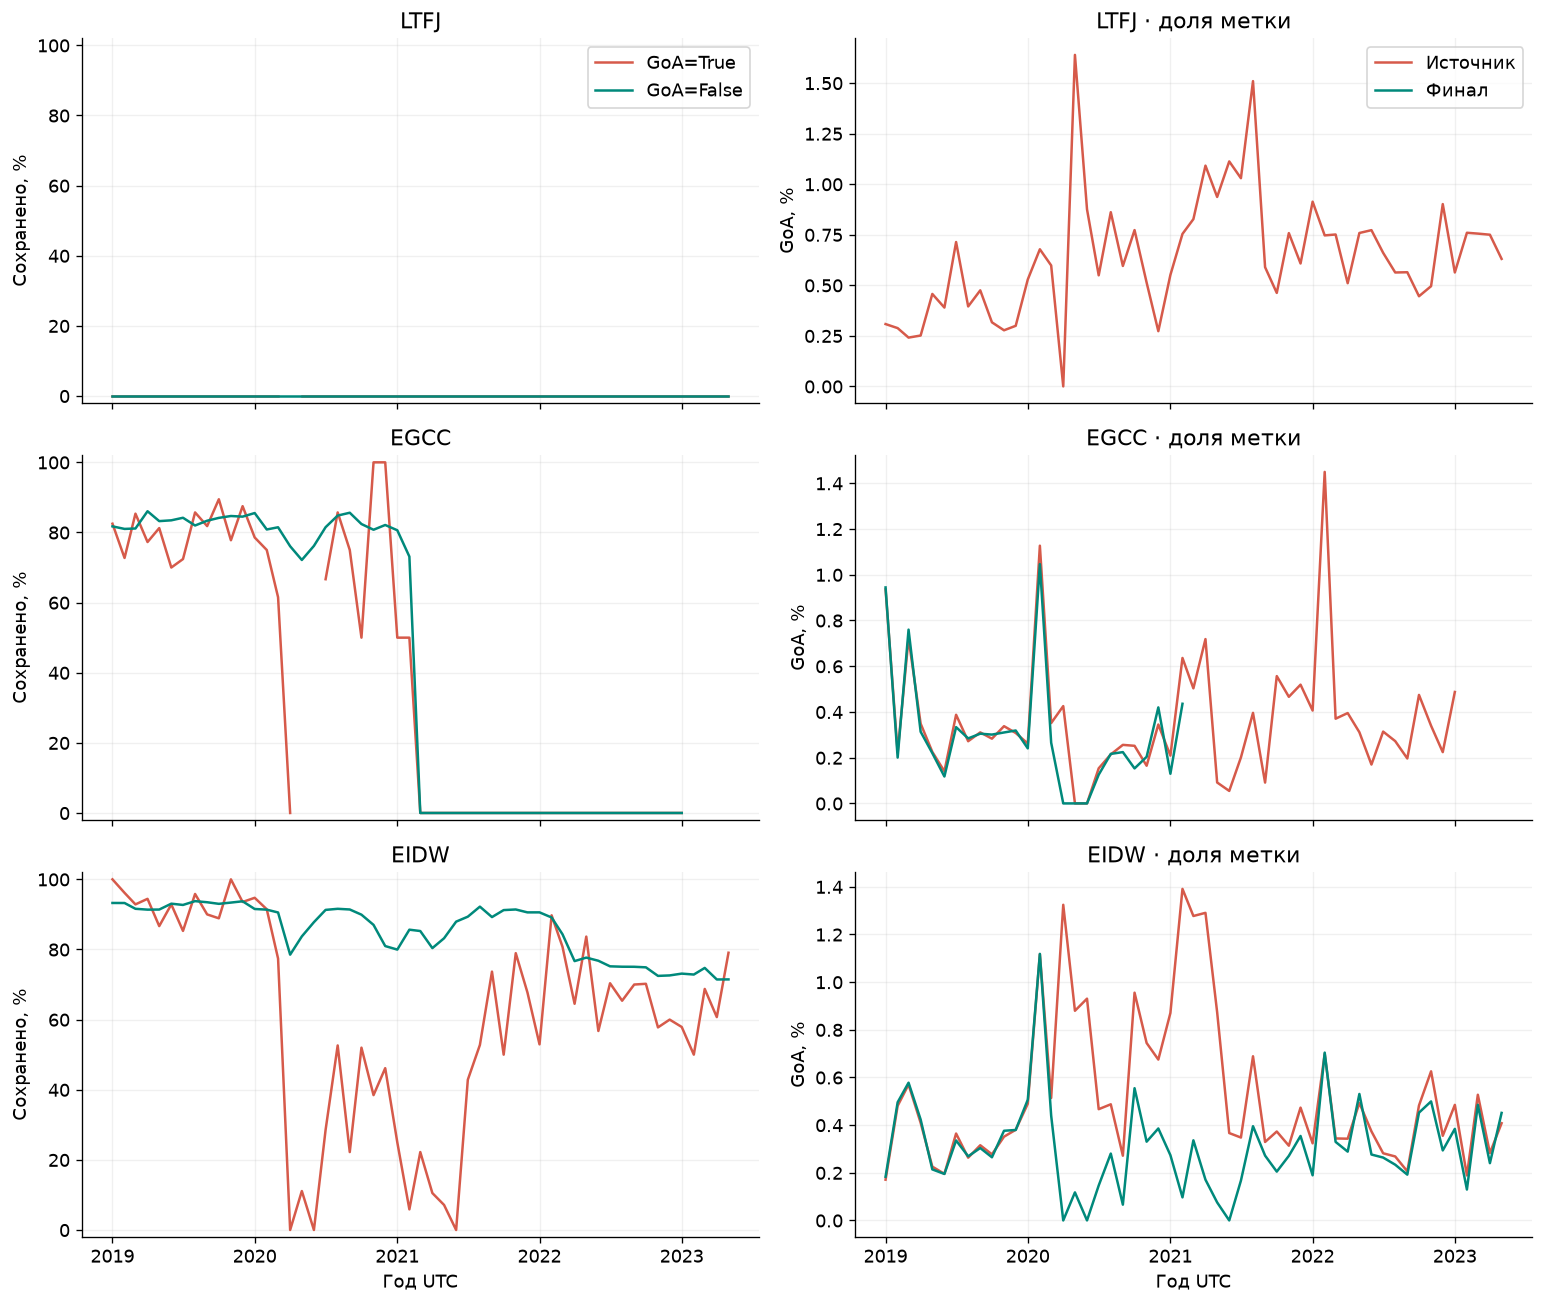

,rows_final,composition_pp,within_pp,delta_pp
airport,,,,
LTFJ,0,nan,nan,nan
EGCC,87435,-0.00562,-0.01876,-0.02438
EIDW,263879,0.00113,-0.08366,-0.08254


In [5]:
focus=['LTFJ','EGCC','EIDW']
focus_reasons=joint[joint.airport.isin(focus)].groupby(['airport','reason'])[['rows','goa']].sum()
display(focus_reasons)
focus_reasons.to_csv(R/'focus_airport_reasons.csv')
fig,axes=plt.subplots(3,2,figsize=(13,11),sharex=True)
for i,airport in enumerate(focus):
    a=am[am.airport==airport].sort_values('month'); dates=pd.to_datetime(a.month)
    axes[i,0].plot(dates,a.positive_retained_pct,label='GoA=True',color='#D65A4A')
    axes[i,0].plot(dates,a.negative_retained_pct,label='GoA=False',color='#00897B')
    axes[i,0].set_ylim(-2,102); axes[i,0].set_ylabel('Сохранено, %'); axes[i,0].set_title(airport)
    axes[i,1].plot(dates,100*a.p0,label='Источник',color='#D65A4A')
    axes[i,1].plot(dates,100*a.p1,label='Финал',color='#00897B')
    axes[i,1].set_ylabel('GoA, %'); axes[i,1].set_title(airport+' · доля метки')
axes[0,0].legend(); axes[0,1].legend()
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.set_xlabel('Год UTC')
save('11_focus_airport_months')
# Вклад календарного состава и внутреннего изменения отдельно для аэропортов.
focus_decomposition=[]
for airport in focus:
    c=comparisons['airport_month'].loc[airport].copy()
    n0=c.rows_source.sum(); n1=c.rows_final.sum()
    if n1==0:
        focus_decomposition.append({'airport':airport,'rows_final':0,'composition_pp':np.nan,'within_pp':np.nan})
        continue
    w0=c.rows_source/n0; w1=c.rows_final/n1
    comp=100*((w1-w0)*c.p0).sum(); within=100*(w1*(c.p1.fillna(c.p0)-c.p0)).sum()
    delta=100*(c.goa_final.sum()/n1-c.goa_source.sum()/n0)
    assert np.isclose(comp+within,delta,atol=1e-12)
    focus_decomposition.append({'airport':airport,'rows_final':int(n1),'delta_pp':delta,
                               'composition_pp':comp,'within_pp':within})
focus_decomposition=pd.DataFrame(focus_decomposition).set_index('airport')
focus_decomposition.to_csv(R/'focus_month_decomposition.csv')
display(focus_decomposition.style.format(precision=5))

## 6. Отсутствующий typecode и C40

Показываем пересечения, затем сравниваем сохранение двух групп типа в одинаковых
стратах аэропорт × месяц. Используем только страты, где обе группы присутствуют
в источнике, с общими весами по суммарному исходному объему страты.
Это описательная стандартизация по двум наблюдаемым признакам, не коррекция
смещения модели и не доказательство случайного механизма пропусков.

,type_missing,reason,rows,goa
0,False,ambiguous_pair,266,3
1,False,c40_not_before_first_attempt,84,45
2,False,manual_case,9,9
3,False,missing_c40,539989,3735
4,False,retained,6109814,17648
5,True,ambiguous_pair,28,0
6,True,missing_c40,1112393,4112
7,True,retained,221671,701


,type_missing,c40_missing_pattern,rows,goa
0,False,0,6110173,17705
1,False,15,539989,3735
2,True,0,221699,701
3,True,15,1112393,4112


,rows_source,rows_final,retained_pct
type_missing,,,
False,6650162,6109814.0,91.874664
True,1334092,221671.0,16.615871


,standardized_retained_pct
type_missing,
False,90.978197
True,19.454120


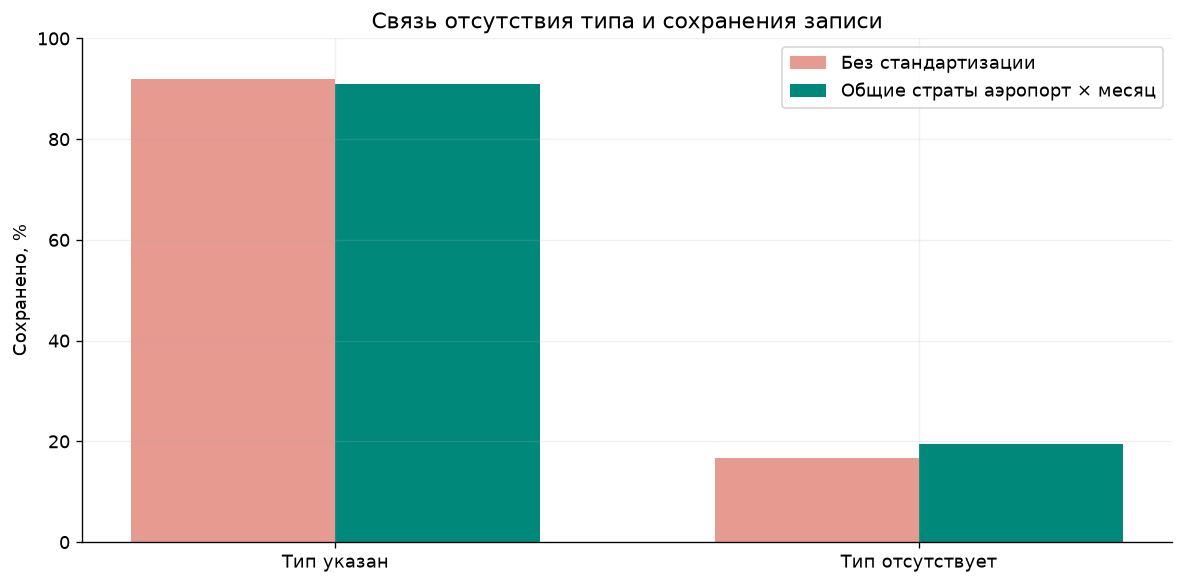

In [6]:
type_reason=joint.groupby(['type_missing','reason'])[['rows','goa']].sum().reset_index()
type_reason.to_csv(R/'type_missing_reason_cross.csv',index=False); display(type_reason)
type_patterns=patterns.groupby(['type_missing','c40_missing_pattern'])[['rows','goa']].sum().reset_index()
type_patterns.to_csv(R/'type_c40_missing_patterns.csv',index=False); display(type_patterns)
c=comparisons['airport_month_type_missing'].reset_index()
strata=c.pivot(index=['airport','month'],columns='type_missing',values=['rows_source','rows_final'])
common=strata['rows_source'][False].notna()&strata['rows_source'][True].notna()
q=strata.loc[common].copy()
weight=q['rows_source'].sum(axis=1); weight=weight/weight.sum()
retention=q['rows_final'].fillna(0)/q['rows_source']
standardized=100*retention.mul(weight,axis=0).sum()
raw=c.groupby('type_missing')[['rows_source','rows_final']].sum()
raw['retained_pct']=100*raw.rows_final/raw.rows_source
display(raw); display(standardized.rename('standardized_retained_pct').to_frame())
type_summary={'common_strata':int(common.sum()),
 'source_rows_in_common_strata':int(q['rows_source'].sum().sum()),
 'standardized_type_present_pct':float(standardized[False]),
 'standardized_type_missing_pct':float(standardized[True]),
 'standardized_gap_pp':float(standardized[True]-standardized[False]),
 'raw_type_present_pct':float(raw.loc[False,'retained_pct']),
 'raw_type_missing_pct':float(raw.loc[True,'retained_pct']),
 'interpretation':'descriptive common airport-month standardization; not causal or model correction'}
(R/'type_missing_standardization.json').write_text(json.dumps(type_summary,indent=2),encoding='utf-8')
plt.figure(figsize=(10,5)); x=np.arange(2); w=.35
plt.bar(x-w/2,[raw.loc[False,'retained_pct'],raw.loc[True,'retained_pct']],w,
         label='Без стандартизации',color='#E69A90')
plt.bar(x+w/2,[standardized[False],standardized[True]],w,
         label='Общие страты аэропорт × месяц',color='#00897B')
plt.xticks(x,['Тип указан','Тип отсутствует']); plt.ylim(0,100)
plt.ylabel('Сохранено, %'); plt.legend(); plt.title('Связь отсутствия типа и сохранения записи')
save('12_type_missing_standardization')

## 7. Литература и ограничения вывода

Небольшой обзор сохранен в `literature/01_selection_review.md`, с указанием
проверенных разделов и границ прочтения. Он не является систематическим поиском.

[Bickel, Brückner, Scheffer (2009), раздел 2](https://jmlr.org/papers/volume10/bickel09a/bickel09a.pdf)
обсуждают предпосылки коррекции covariate shift: общую поддержку и сохранение
условного распределения метки. Их выполнение здесь не доказано.
Нулевое покрытие аэропорта нельзя исправить присвоением весов наблюдениям,
которых в аналитической выборке нет.

Различие сохранения меток внутри аэропорта × месяца еще не устанавливает MNAR:
остаются ненаблюдаемые или неучтенные характеристики. Также нет оценки изменения
качества модели, потому что модель не обучалась. Разложение не уникально:
другая опорная популяция или группировка изменит компоненты при том же общем итоге.

In [7]:
a=decomposition.loc['airport']; b=decomposition.loc['airport_month']
e=focus_decomposition.loc['EIDW']; gap=type_summary['standardized_gap_pp']
egcc_window=zero_windows[zero_windows.airport=='EGCC'].sort_values('observed_months').iloc[-1]
text=f"""### Итоги углубленного эксперимента A

- Общая разница доли GoA: **{a.delta_pp:+.5f} п.п.**
- При группировке по аэропортам: изменение весов **{a.composition_pp:+.5f} п.п.**,
  изменение внутри аэропортов **{a.within_pp:+.5f} п.п.**
- При группировке аэропорт × месяц: изменение весов **{b.composition_pp:+.5f} п.п.**,
  изменение внутри совместных групп **{b.within_pp:+.5f} п.п.**
- Условное ограничение источника аэропортами, представленными в финале,
  меняет исходную долю на **{a.absent_group_support_pp:+.5f} п.п.**;
  оставшаяся разница на общей поддержке – **{a.common_support_delta_pp:+.5f} п.п.**
- В EIDW календарный состав дает **{e.composition_pp:+.5f} п.п.**, а изменения
  внутри месяцев – **{e.within_pp:+.5f} п.п.**
- В EGCC с **{egcc_window.start_month} по {egcc_window.end_month}** нет сохраненных
  наблюдений при **{int(egcc_window.rows_source):,}** исходных записях и
  **{int(egcc_window.goa_source):,}** GoA. Причина в проверенных данных:
  **{egcc_window.reasons}**. Причина прекращения покрытия во времени не установлена.
- После стандартизации по общим стратам аэропорт × месяц сохранение записей
  без типа отличается от группы с типом на **{gap:+.2f} п.п.**

Баланс разложений и совместные группы финала проверены. Отбор меняет доступную
популяцию несколькими путями; общий эффект нельзя автоматически приписать
только исчезновению одного аэропорта или календарному составу.

Материал стал содержательнее для статьи о формировании аналитической выборки.
Самостоятельность публикационного результата пока не установлена: первичный
обзор необходимо расширить до подготовки статьи. Следующий эксперимент –
временная доступность признаков к C40, с отдельным протоколом.
"""
display(Markdown(text)); (R/'structure_findings.md').write_text(text,encoding='utf-8')

### Итоги углубленного эксперимента A

- Общая разница доли GoA: **-0.03900 п.п.**
- При группировке по аэропортам: изменение весов **-0.01500 п.п.**,
  изменение внутри аэропортов **-0.02400 п.п.**
- При группировке аэропорт × месяц: изменение весов **-0.01581 п.п.**,
  изменение внутри совместных групп **-0.02319 п.п.**
- Условное ограничение источника аэропортами, представленными в финале,
  меняет исходную долю на **-0.01501 п.п.**;
  оставшаяся разница на общей поддержке – **-0.02399 п.п.**
- В EIDW календарный состав дает **+0.00113 п.п.**, а изменения
  внутри месяцев – **-0.08366 п.п.**
- В EGCC с **2021-03 по 2023-01** нет сохраненных
  наблюдений при **106,096** исходных записях и
  **401** GoA. Причина в проверенных данных:
  **missing_c40**. Причина прекращения покрытия во времени не установлена.
- После стандартизации по общим стратам аэропорт × месяц сохранение записей
  без типа отличается от группы с типом на **-71.52 п.п.**

Баланс разложений и совместные группы финала проверены. Отбор меняет доступную
популяцию несколькими путями; общий эффект нельзя автоматически приписать
только исчезновению одного аэропорта или календарному составу.

Материал стал содержательнее для статьи о формировании аналитической выборки.
Самостоятельность публикационного результата пока не установлена: первичный
обзор необходимо расширить до подготовки статьи. Следующий эксперимент –
временная доступность признаков к C40, с отдельным протоколом.


1463